# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73287, Beatriz Guerreiro, br.guerreiro@campus.fct.pt
- 73986, Maria Francisca Inácio, mf.inacio@campus.fct.pt

## 1. Introduction

## 2. Part 1 - Frame dissimilarity and hard cuts

In [32]:
import tp1
import cv2 as cv
import matplotlib.pyplot as plt
import plotting
import numpy as np
import metrics
import json
import plotting
from IPython.display import display, Math
import colorsys
import grouping


In [2]:
girls_rot = cv.imread("../girls_closeup_rot.jpg")
girls = cv.imread("../girls_closeup.jpg")
trees = cv.imread("../trees.jpg")


In [4]:
def dif_signals(path_video, path_json):
  video = cv.VideoCapture(path_video)
  with open(path_json, "r") as file:
    data = json.load(file)

  fps = data["fps"]
  total_frames = data["num_frames"]

  d_pixel, d_hist, d_ecr = [], [], []

  _, prev_frame = video.read()
  for i in range(total_frames-1):
    ret, frame = video.read()

    if not ret:
      break

    hist1 = tp1.bgr_histogram(prev_frame)
    hist2 = tp1.bgr_histogram(frame)

    pixel_dif = tp1.pixel_difference(prev_frame, frame)
    hist_dif = tp1.histogram_distance(hist1, hist2)
    ecr = tp1.edge_change_ration(prev_frame, frame)

    d_pixel.append(pixel_dif)
    d_hist.append(hist_dif)
    d_ecr.append(ecr)

    prev_frame = frame

  video.release()

  signals = {"histogram": d_hist, "pixel": d_pixel, "ecr":d_ecr}
  return signals, data, fps


In [5]:
signals1, data1, fps1 = dif_signals("../input/dev_01.mp4", "../input/dev_01.json")
signals2, data2, fps2 = dif_signals("../input/dev_02.mp4", "../input/dev_02.json")

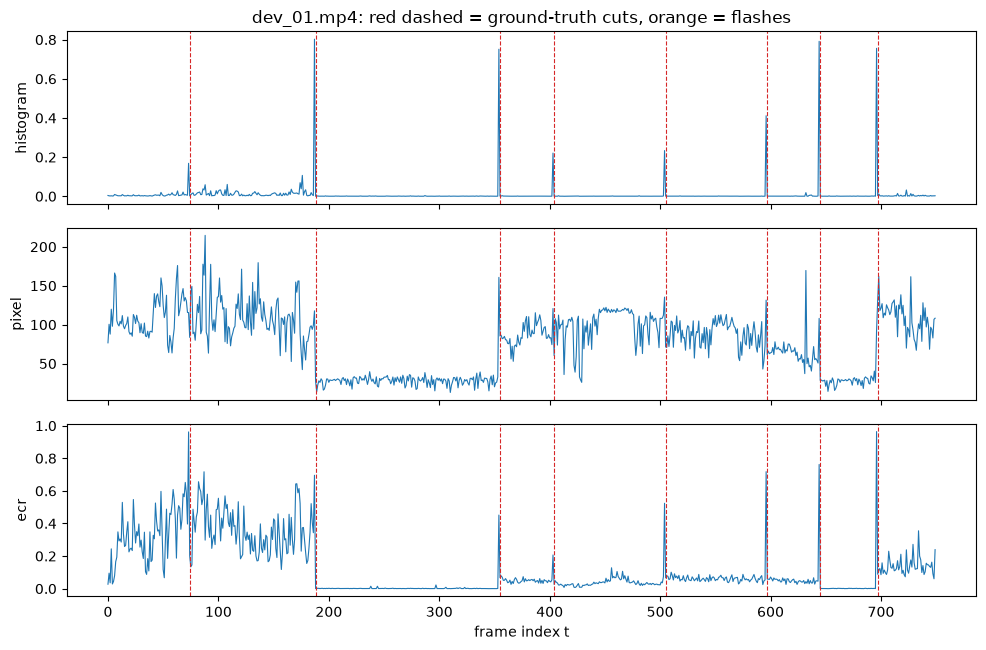

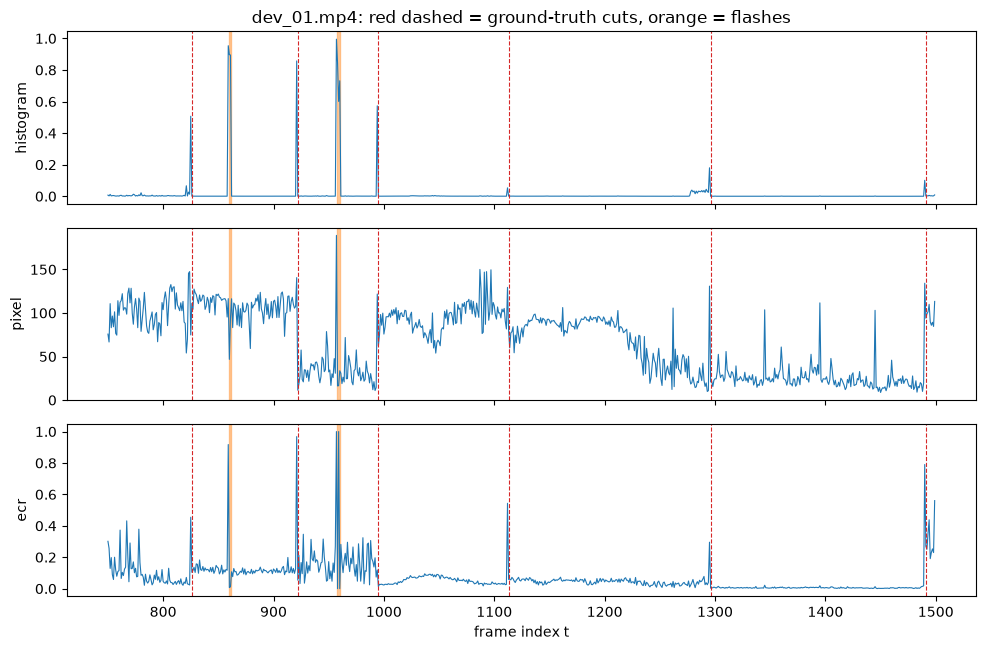

In [5]:
segs = 30

# plot dos primeiros 30s
plotting.plot_signals(signals=signals1, gt=data1, start=0, end=fps1*segs)

#plot dos 30 aos 60s
plotting.plot_signals(signals=signals1, gt=data1, start=fps1*segs, end=fps1*segs*2)
print()

In [8]:
cuts_ind_hist = tp1.detect_cuts(signals1["histogram"], 0.122)
cuts_ind_ecr = tp1.detect_cuts(signals1["ecr"], 0.653)
cuts_ind_pixel = tp1.detect_cuts(signals1["pixel"], 0.127)

cuts_hist = tp1.cut_list_to_transitions(cuts_ind_hist)
cuts_ecr = tp1.cut_list_to_transitions(cuts_ind_ecr)
cuts_pixel = tp1.cut_list_to_transitions(cuts_ind_pixel)

dict_dev1_h = metrics.evaluate_video(data1, cuts_hist)
dict_dev1_e = metrics.evaluate_video(data1, cuts_ecr)
dict_dev1_p = metrics.evaluate_video(data1, cuts_pixel)

metrics.print_table((("hist", dict_dev1_h), ("ecr", dict_dev1_e), ("pixel", dict_dev1_p)))

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
hist        0.846  0.917   0.880       6/6    0.000    0.000     0.000
ecr         0.577  0.417   0.484       3/6    0.000    0.000     0.000
pixel       0.052  0.917   0.098       6/6    0.000    0.000     0.000


In [9]:
def add_signal_to_curve(curves_dict, signal_name, videos, t_min=0.05, t_max=0.95, num_steps=50, min_gap = 5):
  curves_dict[signal_name] = []
  for T in np.linspace(t_min, t_max, num_steps):

    tp_total = fp_total = fn_total = 0

    for signal_values, gt_cuts in videos: 
      pred_cuts = tp1.merge_close([i + 1 for i, val in enumerate(signal_values) if val > T], min_gap)
      tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)

      tp_total += tp
      fp_total += fp
      fn_total += fn 

    p, r, f1 = metrics.precision_recall_f1(tp_total, fp_total, fn_total)
    
    curves_dict[signal_name].append((T, p, r, f1))
        
  return curves_dict

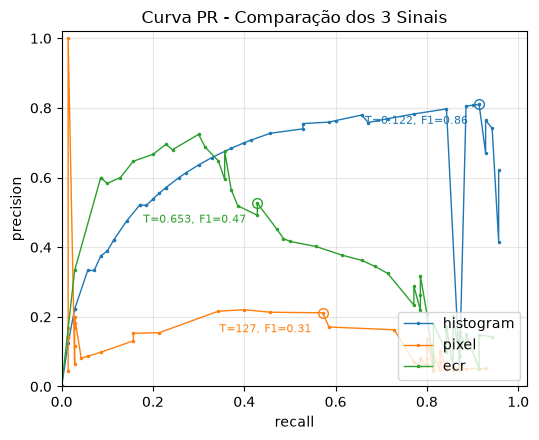

In [12]:
curves = {}

gt_cuts1 = [t["start"] for t in data1["transitions"]] 
gt_cuts2 = [t["start"] for t in data2["transitions"]] 

d_hist1 = signals1["histogram"]
d_pixel1 = signals1["pixel"]
d_ecr1 = signals1["ecr"]

d_hist2 = signals2["histogram"]
d_pixel2 = signals2["pixel"]
d_ecr2 = signals2["ecr"]

hists = [(d_hist1, gt_cuts1), (d_hist2, gt_cuts2)]
ecrs = [(d_ecr1, gt_cuts1), (d_ecr2, gt_cuts2)]
pixels = [(d_pixel1, gt_cuts1), (d_pixel2, gt_cuts2)]

add_signal_to_curve(curves, "histogram", hists, t_min=0.0, t_max=1.0)
add_signal_to_curve(curves, "pixel", pixels, t_min=0.0, t_max=max(d_pixel1))
add_signal_to_curve(curves, "ecr", ecrs, t_min=0.0, t_max=1.0)

fig = plotting.plot_pr_curve(curves, title="Curva PR - Comparação dos 3 Sinais", path="../output/pr_curve_all_signals.png")

In [13]:
gt_cuts1 = [t["start"] for t in data1["transitions"]] 

tp1.print_metrics(cuts_ind_hist, gt_cuts1)

true positives: 33
false positives: 6
FN?: 3
precision: 0.8461538461538461
recall: 0.9166666666666666
f1: 0.8799999999999999


In [19]:
cuts_ind_hist = tp1.detect_cuts(signals2["histogram"], 0.122)
cuts_hist = tp1.cut_list_to_transitions(cuts_ind_hist)
dict_dev2_h = metrics.evaluate_video(data2, cuts_hist)

sum = metrics.sum_counts([dict_dev1_h, dict_dev2_h])
metrics.print_table([("Sum", sum)])

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
Sum         0.810  0.914   0.859     12/12    0.000    0.000     0.000


In [14]:
T_h = 0.122
T_e = 0.653

def evaluate_both(use_hist, use_ecr, mode="or"):
    TP = FP = FN = 0
    for h, e, gt in [(d_hist1, d_ecr1, gt_cuts1), (d_hist2, d_ecr2, gt_cuts2)]:
        pred = []
        for i in range(len(h)):
            a = h[i] > T_h
            b = e[i] > T_e
            if use_hist and not use_ecr:
                cut = a
            elif use_ecr and not use_hist:
                cut = b
            elif mode == "or":
                cut = a or b
            else:
                cut = a and b
            if cut:
                pred.append(i + 1)
        pred = tp1.merge_close(pred)
        tp, fp, fn = metrics.match_cuts(gt, pred)
        TP += tp; FP += fp; FN += fn
    return metrics.precision_recall_f1(TP, FP, FN)

print("hist:", evaluate_both(True, False))
print("ecr: ", evaluate_both(False, True))
print("OR:  ", evaluate_both(True, True, "or"))
print("AND: ", evaluate_both(True, True, "and"))

hist: (0.810126582278481, 0.9142857142857143, 0.8590604026845637)
ecr:  (0.5263157894736842, 0.42857142857142855, 0.4724409448818898)
OR:   (0.6530612244897959, 0.9142857142857143, 0.7619047619047618)
AND:  (0.7894736842105263, 0.42857142857142855, 0.5555555555555555)


## 3. Part 2 - Gradual transitions and false alarms

In [20]:
frames1 = tp1.read_frames("../input/dev_01.mp4")
frames2 = tp1.read_frames("../input/dev_02.mp4")

In [19]:
def test_false_alarms(frame1, frame2):
    gray1 = cv.cvtColor(frame1, cv.COLOR_BGR2GRAY)
    gray2 = cv.cvtColor(frame2, cv.COLOR_BGR2GRAY)

    sift = cv.SIFT_create()
    _, des1 = sift.detectAndCompute(gray1, None)
    _, des2 = sift.detectAndCompute(gray2, None)

    if des1 is None or des2 is None or len(des1) < 2 or len(des2) < 2:
        return 0.0

    des1 = des1.astype(np.float32)
    des2 = des2.astype(np.float32)

    bf = cv.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)

    good = []
    if len(matches) == 0: return 0.0
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good.append([m])

    return float(len(good)) / float(len(matches))

In [25]:
transitions_before_sift = tp1.process_video(frames1, gt_shots=None, verify=False)
transitions_after_sift = tp1.process_video(frames1, gt_shots=None, verify=True)

results_without = metrics.evaluate_video(data1, transitions_before_sift)
results_with = metrics.evaluate_video(data1, transitions_after_sift)

metrics.print_table((("Without", results_without), ("With", results_with)))


video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
Without     0.846  0.917   0.880       6/6    0.000    0.000     0.000
With        1.000  0.917   0.957       0/6    0.000    0.000     0.000


In [26]:
transitions_before_sift = tp1.process_video(frames2, gt_shots=None, verify=False)
transitions_after_sift = tp1.process_video(frames2, gt_shots=None, verify=True)

results_without = metrics.evaluate_video(data2, transitions_before_sift)
results_with = metrics.evaluate_video(data2, transitions_after_sift)

metrics.print_table((("Without", results_without), ("With", results_with)))

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
Without     0.775  0.912   0.838       6/6    0.000    0.000     0.000
With        0.912  0.912   0.912       1/6    0.000    0.000     0.000


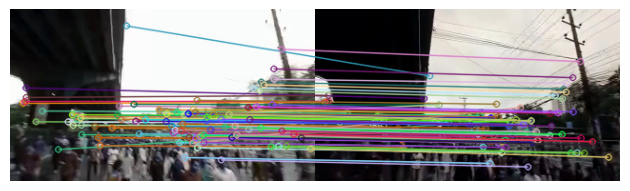

In [43]:
transitions_without = [t["start"] for t in transitions_before_sift["transitions"]]
transitions_with = [t["start"] for t in transitions_after_sift["transitions"]]

false_alarms = list(set(transitions_without) - set(transitions_with))
fa = false_alarms[0]

f1 = frames2[fa - tp1.GAP]
f2 = frames2[fa + tp1.GAP]

g, m, k1, k2 = tp1.sift_matches(f1, f2)
img = cv.drawMatchesKnn(f1, k1, f2, k2, g, None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.imshow(img)
plt.axis("off")
plt.tight_layout()
plt.show()

cuts:    n=70  min=0.000  max=0.169  mean=0.015
flashes: n=12  min=0.054  max=0.690  mean=0.488

T = 0.110  (plateau 0.052 to 0.054)
cuts kept: 98.6%   flashes rejected: 91.7%


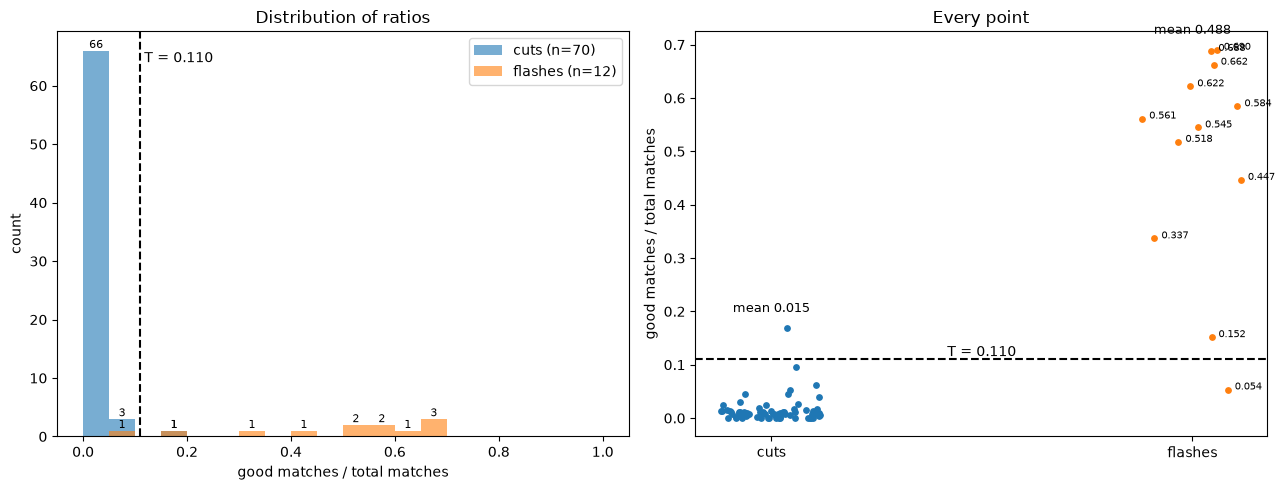

In [40]:
cuts1 = [t["start"] for t in data1["transitions"]]
cuts2 = [t["start"] for t in data2["transitions"]]

flashes1 = [t["start"] for t in data1["distractors"]]
flashes2 = [t["start"] for t in data2["distractors"]]

frames  = [frames1, frames2]
cuts    = [cuts1, cuts2]
flashes = [flashes1, flashes2]

# ---------- score every cut / flash of every video ----------
def scores_at(frames_v, positions, gap=4):
    scores = []
    for t in positions:
        a, b = t - gap, t + gap
        if a < 0 or b >= len(frames_v):
            continue
        g, m, _, _ = tp1.sift_matches(frames_v[a], frames_v[b])
        scores.append(len(g) / len(m))
    return scores


cuts_list, flashes_list = [], []
for fr, c, f in zip(frames, cuts, flashes):
    cuts_list += scores_at(fr, c)
    flashes_list += scores_at(fr, f)

cut_ratios = np.array(cuts_list)
flash_ratios = np.array(flashes_list)

np.save("../output/cut_ratios.npy", cut_ratios) # to don't recompute SIFT
np.save("../output/flash_ratios.npy", flash_ratios)

print(f"cuts:    n={len(cut_ratios)}  min={cut_ratios.min():.3f}  max={cut_ratios.max():.3f}  mean={cut_ratios.mean():.3f}")
print(f"flashes: n={len(flash_ratios)}  min={flash_ratios.min():.3f}  max={flash_ratios.max():.3f}  mean={flash_ratios.mean():.3f}")

ratios = np.concatenate([cut_ratios, flash_ratios])
labels = np.concatenate([np.ones(len(cut_ratios)), np.zeros(len(flash_ratios))]).astype(bool)

Ts = np.unique(ratios)
J = np.array([np.mean((ratios < T)[labels]) - np.mean((ratios < T)[~labels]) for T in Ts])
good_Ts = Ts[J >= J.max() - 0.02]          # plateau of near-best thresholds
#T = float(np.median(good_Ts))              # middle of the plateau, generalizes better
T = 0.11

kept_cuts   = np.mean(cut_ratios < T)      # real cuts correctly kept
rejected_fl = np.mean(flash_ratios >= T)   # flashes correctly rejected
print(f"\nT = {T:.3f}  (plateau {good_Ts.min():.3f} to {good_Ts.max():.3f})")
print(f"cuts kept: {kept_cuts:.1%}   flashes rejected: {rejected_fl:.1%}")




# ---------- plots with exact numbers ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(0, 1, 21)
for data, name in [(cut_ratios, "cuts"), (flash_ratios, "flashes")]:
    counts, _, patches = ax1.hist(data, bins=bins, alpha=.6, label=f"{name} (n={len(data)})")
    ax1.bar_label(patches, labels=[int(c) if c > 0 else "" for c in counts], fontsize=8)
ax1.axvline(T, color="k", ls="--")
ax1.text(T, ax1.get_ylim()[1] * 0.95, f" T = {T:.3f}", va="top")
ax1.set_xlabel("good matches / total matches")
ax1.set_ylabel("count")
ax1.set_title("Distribution of ratios")
ax1.legend()

for x, data in [(0, cut_ratios), (1, flash_ratios)]:
    jitter = np.random.uniform(-.12, .12, len(data))
    ax2.scatter(x + jitter, data, s=15)
    if len(data) <= 30:                                   # label points only if readable
        for j, v in zip(jitter, data):
            ax2.annotate(f"{v:.3f}", (x + j, v), xytext=(5, 0),
                         textcoords="offset points", fontsize=7)
    ax2.text(x, data.max() + 0.03, f"mean {data.mean():.3f}", ha="center", fontsize=9)
ax2.axhline(T, color="k", ls="--")
ax2.text(0.5, T, f"T = {T:.3f}", ha="center", va="bottom")
ax2.set_xticks([0, 1], ["cuts", "flashes"])
ax2.set_ylabel("good matches / total matches")
ax2.set_title("Every point")

plt.tight_layout()
plt.savefig("../output/ratios_cuts_vs_flashes.png", dpi=150)
plt.show()

## 4. Part 3 - Recurring scenes

### Task 5 - Shot Representation

In [6]:
# Exemplo da tua lista de shots (ou podes carregar do ficheiro JSON)
shots_data = [
    {"id": 0, "start": 0, "end": 73, "scene": "S00"},
    {"id": 1, "start": 74, "end": 187, "scene": "S01"},
    {"id": 2, "start": 188, "end": 354, "scene": "S02"},
]

def test_keyframe_stategy(strategy):
    print(f"\n--- A testar a estratégia: {strategy} ---")
    for shot in shots_data:
        shot_id = shot["id"]

        # Chamar a tua função para obter os índices dos keyframes deste shot
        kfs_indices = tp1.extract_keyframes(shot, strategy=strategy, num_kfs=12)

        print(f"Shot {shot_id} (Duração: {shot['start']} até {shot['end']}) -> Keyframes nos índices: {kfs_indices}")

test_keyframe_stategy("single_fst")
test_keyframe_stategy("single_middle")
test_keyframe_stategy("fst_middle_last")
test_keyframe_stategy("multiple_eq")
test_keyframe_stategy("random")
test_keyframe_stategy("random_10%")



--- A testar a estratégia: single_fst ---
Shot 0 (Duração: 0 até 73) -> Keyframes nos índices: [0]
Shot 1 (Duração: 74 até 187) -> Keyframes nos índices: [74]
Shot 2 (Duração: 188 até 354) -> Keyframes nos índices: [188]

--- A testar a estratégia: single_middle ---
Shot 0 (Duração: 0 até 73) -> Keyframes nos índices: [36]
Shot 1 (Duração: 74 até 187) -> Keyframes nos índices: [130]
Shot 2 (Duração: 188 até 354) -> Keyframes nos índices: [271]

--- A testar a estratégia: fst_middle_last ---
Shot 0 (Duração: 0 até 73) -> Keyframes nos índices: [0, 36, 73]
Shot 1 (Duração: 74 até 187) -> Keyframes nos índices: [74, 130, 187]
Shot 2 (Duração: 188 até 354) -> Keyframes nos índices: [188, 271, 354]

--- A testar a estratégia: multiple_eq ---
Shot 0 (Duração: 0 até 73) -> Keyframes nos índices: [0, 6, 13, 19, 26, 33, 39, 46, 53, 59, 66, 73]
Shot 1 (Duração: 74 até 187) -> Keyframes nos índices: [74, 84, 94, 104, 115, 125, 135, 145, 156, 166, 176, 187]
Shot 2 (Duração: 188 até 354) -> Keyfra

In [7]:
# Dois shots muito semelhantes (vários keyframes dão match alto)
matrix_similar = [
    [0.85, 0.90, 0.75],
    [0.80, 0.88, 0.70],
    [0.60, 0.65, 0.55]
]

# Um shot com alguma correspondência pontual, mas muito ruído
matrix_mixed = [
    [0.95, 0.10, 0.05],
    [0.20, 0.15, 0.10],
    [0.05, 0.02, 0.01]
]

# Dois shots totalmente diferentes (valores baixos)
matrix_different = [
    [0.12, 0.08, 0.15],
    [0.05, 0.10, 0.09],
    [0.11, 0.04, 0.07]
]

# Diferente número de keyframes (ex: 2 keyframes num shot e 4 noutro)
matrix_asymmetric = [
    [0.75, 0.80, 0.30, 0.10],
    [0.20, 0.25, 0.85, 0.90]
]


methods_to_test = [
    "best_pair", 
    "average", 
    "threshold_count", 
    "weighted_threshold_count", 
    "tiered_weighted_average", 
    "max_mutual_matching"
]

def test_combine_similarities(matrix):
    for method in methods_to_test:
        score = tp1.combine_keyframe_similarities(matrix, method=method)
        print(f"Método '{method:<26}' -> Pontuação Final: {score:.4f}")


print("\n=== Matrix Similar ===")
test_combine_similarities(matrix_similar)
print("\n=== Matrix Mixed ===")
test_combine_similarities(matrix_mixed)
print("\n=== Matrix Different ===")
test_combine_similarities(matrix_different)
print("\n=== Matrix Asymetric ===")
test_combine_similarities(matrix_asymmetric)




=== Matrix Similar ===
Método 'best_pair                 ' -> Pontuação Final: 0.9000
Método 'average                   ' -> Pontuação Final: 0.7422
Método 'threshold_count           ' -> Pontuação Final: 7.0000
Método 'weighted_threshold_count  ' -> Pontuação Final: 0.6000
Método 'tiered_weighted_average   ' -> Pontuação Final: 0.7757
Método 'max_mutual_matching       ' -> Pontuação Final: 0.8100

=== Matrix Mixed ===
Método 'best_pair                 ' -> Pontuação Final: 0.9500
Método 'average                   ' -> Pontuação Final: 0.1811
Método 'threshold_count           ' -> Pontuação Final: 1.0000
Método 'weighted_threshold_count  ' -> Pontuação Final: 0.1111
Método 'tiered_weighted_average   ' -> Pontuação Final: 0.5656
Método 'max_mutual_matching       ' -> Pontuação Final: 0.4000

=== Matrix Different ===
Método 'best_pair                 ' -> Pontuação Final: 0.1500
Método 'average                   ' -> Pontuação Final: 0.0900
Método 'threshold_count           ' -> Pontuaç

### Task 6 Shot similarity

In [8]:
dev_01_json = data1

video_capture = cv.VideoCapture("../input/dev_01.mp4")
shots = dev_01_json["shots"]

shot_similarities = tp1.compute_global_shot_similarity_matrix_full(
    shots, 
    video_capture, 
    kf_strategy="single_middle",
    combination_method="max_mutual_matching",
    alpha=0.5
)

print("Dimensão da matriz global:", shot_similarities.shape)

# ATENCAO ISTO DEMORA 3 MINUTOS A CORRER :)

Dimensão da matriz global: (37, 37)


### Task 7 - Grouping

In [13]:
import grouping as group
import metrics

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
best_f1 = -1
best_threshold = 0

print(f"{'Threshold':<10s} | {'Precision':<10s} | {'Recall':<10s} | {'F1-Score':<10s}")
print("-----------------------------------------------")

# determinar o melhor threshold
for th in thresholds:
    labels = group.group_shots(shot_similarities, threshold=th)
    scenes = {"scenes": {str(s["id"]): label for s, label in zip(shots, labels)}}
    
    counts = metrics.evaluate_video(dev_01_json, scenes)
    p, r, f1 = metrics.precision_recall_f1(*counts["scene"])
    
    print(f"{th:<10.1f} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f}")
    
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = th

print(f"\nMelhor threshold: {best_threshold} com F1-Score {best_f1:.3f}")

Threshold  | Precision  | Recall     | F1-Score  
-----------------------------------------------
0.3        | 0.016      | 0.900      | 0.031     
0.4        | 0.017      | 0.900      | 0.033     
0.5        | 0.022      | 0.900      | 0.043     
0.6        | 0.111      | 0.800      | 0.195     
0.7        | 0.800      | 0.800      | 0.800     
0.8        | 0.778      | 0.700      | 0.737     
0.9        | 1.000      | 0.600      | 0.750     

Melhor threshold: 0.7 com F1-Score 0.800


In [14]:
# ATENCAO ISTO DEMORA 5 OU 6 MINUTOS A CORRER :)

video_capture = cv.VideoCapture("../input/dev_01.mp4")

with open("../input/dev_01.json", "r") as file:
    dev_01_json = json.load(file)

shots = dev_01_json["shots"]

# 4 combinações
configurations = [
    {"name": "Color + 1 KF",       "strategy": "single_middle",    "alpha": 1.0},
    {"name": "Color + Multi KF",     "strategy": "fst_middle_last",  "alpha": 1.0},
    {"name": "Color+SIFT + 1 KF",    "strategy": "single_middle",    "alpha": 0.5},
    {"name": "Color+SIFT + Multi KF","strategy": "fst_middle_last",  "alpha": 0.5},
]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
table_rows = []


for config in configurations:
    print(f"\n========================================")
    print(f"A testar: {config['name']}")
    print(f"========================================")
    
    shot_similarities = tp1.compute_global_shot_similarity_matrix_full(
        shots, 
        video_capture, 
        kf_strategy=config["strategy"],
        combination_method="max_mutual_matching",
        alpha=config["alpha"]
    )
    
    best_f1 = -1
    best_threshold = 0
    best_counts = None
    
    # encontrar melhor threshold para valor de F1
    for th in thresholds:
        labels = group.group_shots(shot_similarities, threshold=th)
        scenes = {"scenes": {str(s["id"]): label for s, label in zip(shots, labels)}}
        
        counts = metrics.evaluate_video(dev_01_json, scenes)
        p, r, f1 = metrics.precision_recall_f1(*counts["scene"])
        
        print(f"  -> Threshold {th:.1f} | Precision: {p:.3f} | Recall: {r:.3f} | F1: {f1:.3f}")
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = th
            best_counts = counts
            
    print(f"Melhor para '{config['name']}': Threshold = {best_threshold} (F1 = {best_f1:.3f})")
    
    label_name = f"{config['name']} (th={best_threshold})"
    table_rows.append((label_name, best_counts))


print("\n\n" + "#"*60)
print(" TABELA FINAL DE AVALIAÇÃO (TASK 7 - DEV SET)")
print("#"*60)
metrics.print_table(table_rows)


A testar: Color + 1 KF


KeyboardInterrupt: 

In [15]:
# ATENCAO ISTO DEMORA 5 OU 6 MINUTOS A CORRER :)

# 4 combinações
configurations = [
    {"name": "Color + 1 KF",       "strategy": "single_middle",    "alpha": 1.0},
    {"name": "Color + Multi KF",     "strategy": "fst_middle_last",  "alpha": 1.0},
    {"name": "Color+SIFT + 1 KF",    "strategy": "single_middle",    "alpha": 0.5},
    {"name": "Color+SIFT + Multi KF","strategy": "fst_middle_last",  "alpha": 0.5},
]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
table_rows = []


for config in configurations:
    print(f"\n========================================")
    print(f"A testar: {config['name']}")
    print(f"========================================")
    
    shot_similarities = tp1.compute_global_shot_similarity_matrix_full(
        shots, 
        video_capture, 
        kf_strategy=config["strategy"],
        combination_method="best_pair",
        alpha=config["alpha"]
    )
    
    best_f1 = -1
    best_threshold = 0
    best_counts = None
    
    # encontrar melhor threshold para valor de F1
    for th in thresholds:
        labels = group.group_shots(shot_similarities, threshold=th)
        scenes = {"scenes": {str(s["id"]): label for s, label in zip(shots, labels)}}
        
        counts = metrics.evaluate_video(dev_01_json, scenes)
        p, r, f1 = metrics.precision_recall_f1(*counts["scene"])
        
        print(f"  -> Threshold {th:.1f} | Precision: {p:.3f} | Recall: {r:.3f} | F1: {f1:.3f}")
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = th
            best_counts = counts
            
    print(f"Melhor para '{config['name']}': Threshold = {best_threshold} (F1 = {best_f1:.3f})")
    
    label_name = f"{config['name']} (th={best_threshold})"
    table_rows.append((label_name, best_counts))


print("\n\n" + "#"*60)
print(" TABELA FINAL DE AVALIAÇÃO (TASK 7 - DEV SET)")
print("#"*60)
metrics.print_table(table_rows)


A testar: Color + 1 KF
  -> Threshold 0.3 | Precision: 0.014 | Recall: 0.900 | F1: 0.028
  -> Threshold 0.4 | Precision: 0.016 | Recall: 0.900 | F1: 0.031
  -> Threshold 0.5 | Precision: 0.016 | Recall: 0.900 | F1: 0.031
  -> Threshold 0.6 | Precision: 0.018 | Recall: 0.900 | F1: 0.036
  -> Threshold 0.7 | Precision: 0.018 | Recall: 0.900 | F1: 0.036
  -> Threshold 0.8 | Precision: 0.024 | Recall: 0.900 | F1: 0.046
  -> Threshold 0.9 | Precision: 0.072 | Recall: 0.800 | F1: 0.132
Melhor para 'Color + 1 KF': Threshold = 0.9 (F1 = 0.132)

A testar: Color + Multi KF


KeyboardInterrupt: 

In [9]:
num_shots = len(shots)
gt_matrix = np.zeros((num_shots, num_shots)) 

for i in range(num_shots):
  for j in range(num_shots):
    if(shots[i].get("scene") == shots[j].get("scene")):
      gt_matrix[i, j] = 1

In [10]:
def bmatrix(M):
    rows = r" \\ ".join(" & ".join(map(str, r)) for r in M)
    return r"\begin{bmatrix}" + rows + r"\end{bmatrix}"

display(Math(bmatrix(np.round(shot_similarities, 2)) + r"\qquad" + bmatrix(gt_matrix)))

<IPython.core.display.Math object>

In [61]:
scenes[0]

KeyError: 0

In [70]:
i = 1
scenes["scenes"][str(i)]

1

In [72]:
i = 0
"Shot "+str(i)+", labled:"+str(scenes["scenes"][str(i)])

'Shot 0, labled:0'

In [73]:
def generate_colors(n, saturation=0.8, value=0.9):
    """Return n evenly spaced colors across the spectrum as hex strings."""
    colors = []
    for i in range(n):
        r, g, b = colorsys.hsv_to_rgb(i / n, saturation, value)
        colors.append((round(r * 255), round(g * 255), round(b * 255)))
    return colors



import math
def show_images(images, per_row=5, size=3, titles=None):
    n = len(images)
    rows = math.ceil(n / per_row)          # 37 / 5 -> 8 rows

    fig, axes = plt.subplots(rows, per_row, figsize=(per_row * size, rows * size))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(images[i])
            if titles is not None:
                ax.set_title("Shot "+str(i)+", labled:"+str(titles["scenes"][str(i)]), fontsize=9)
        ax.axis("off")                      # also hides the unused slots (3 empty ones here)

    plt.tight_layout()
    plt.show()

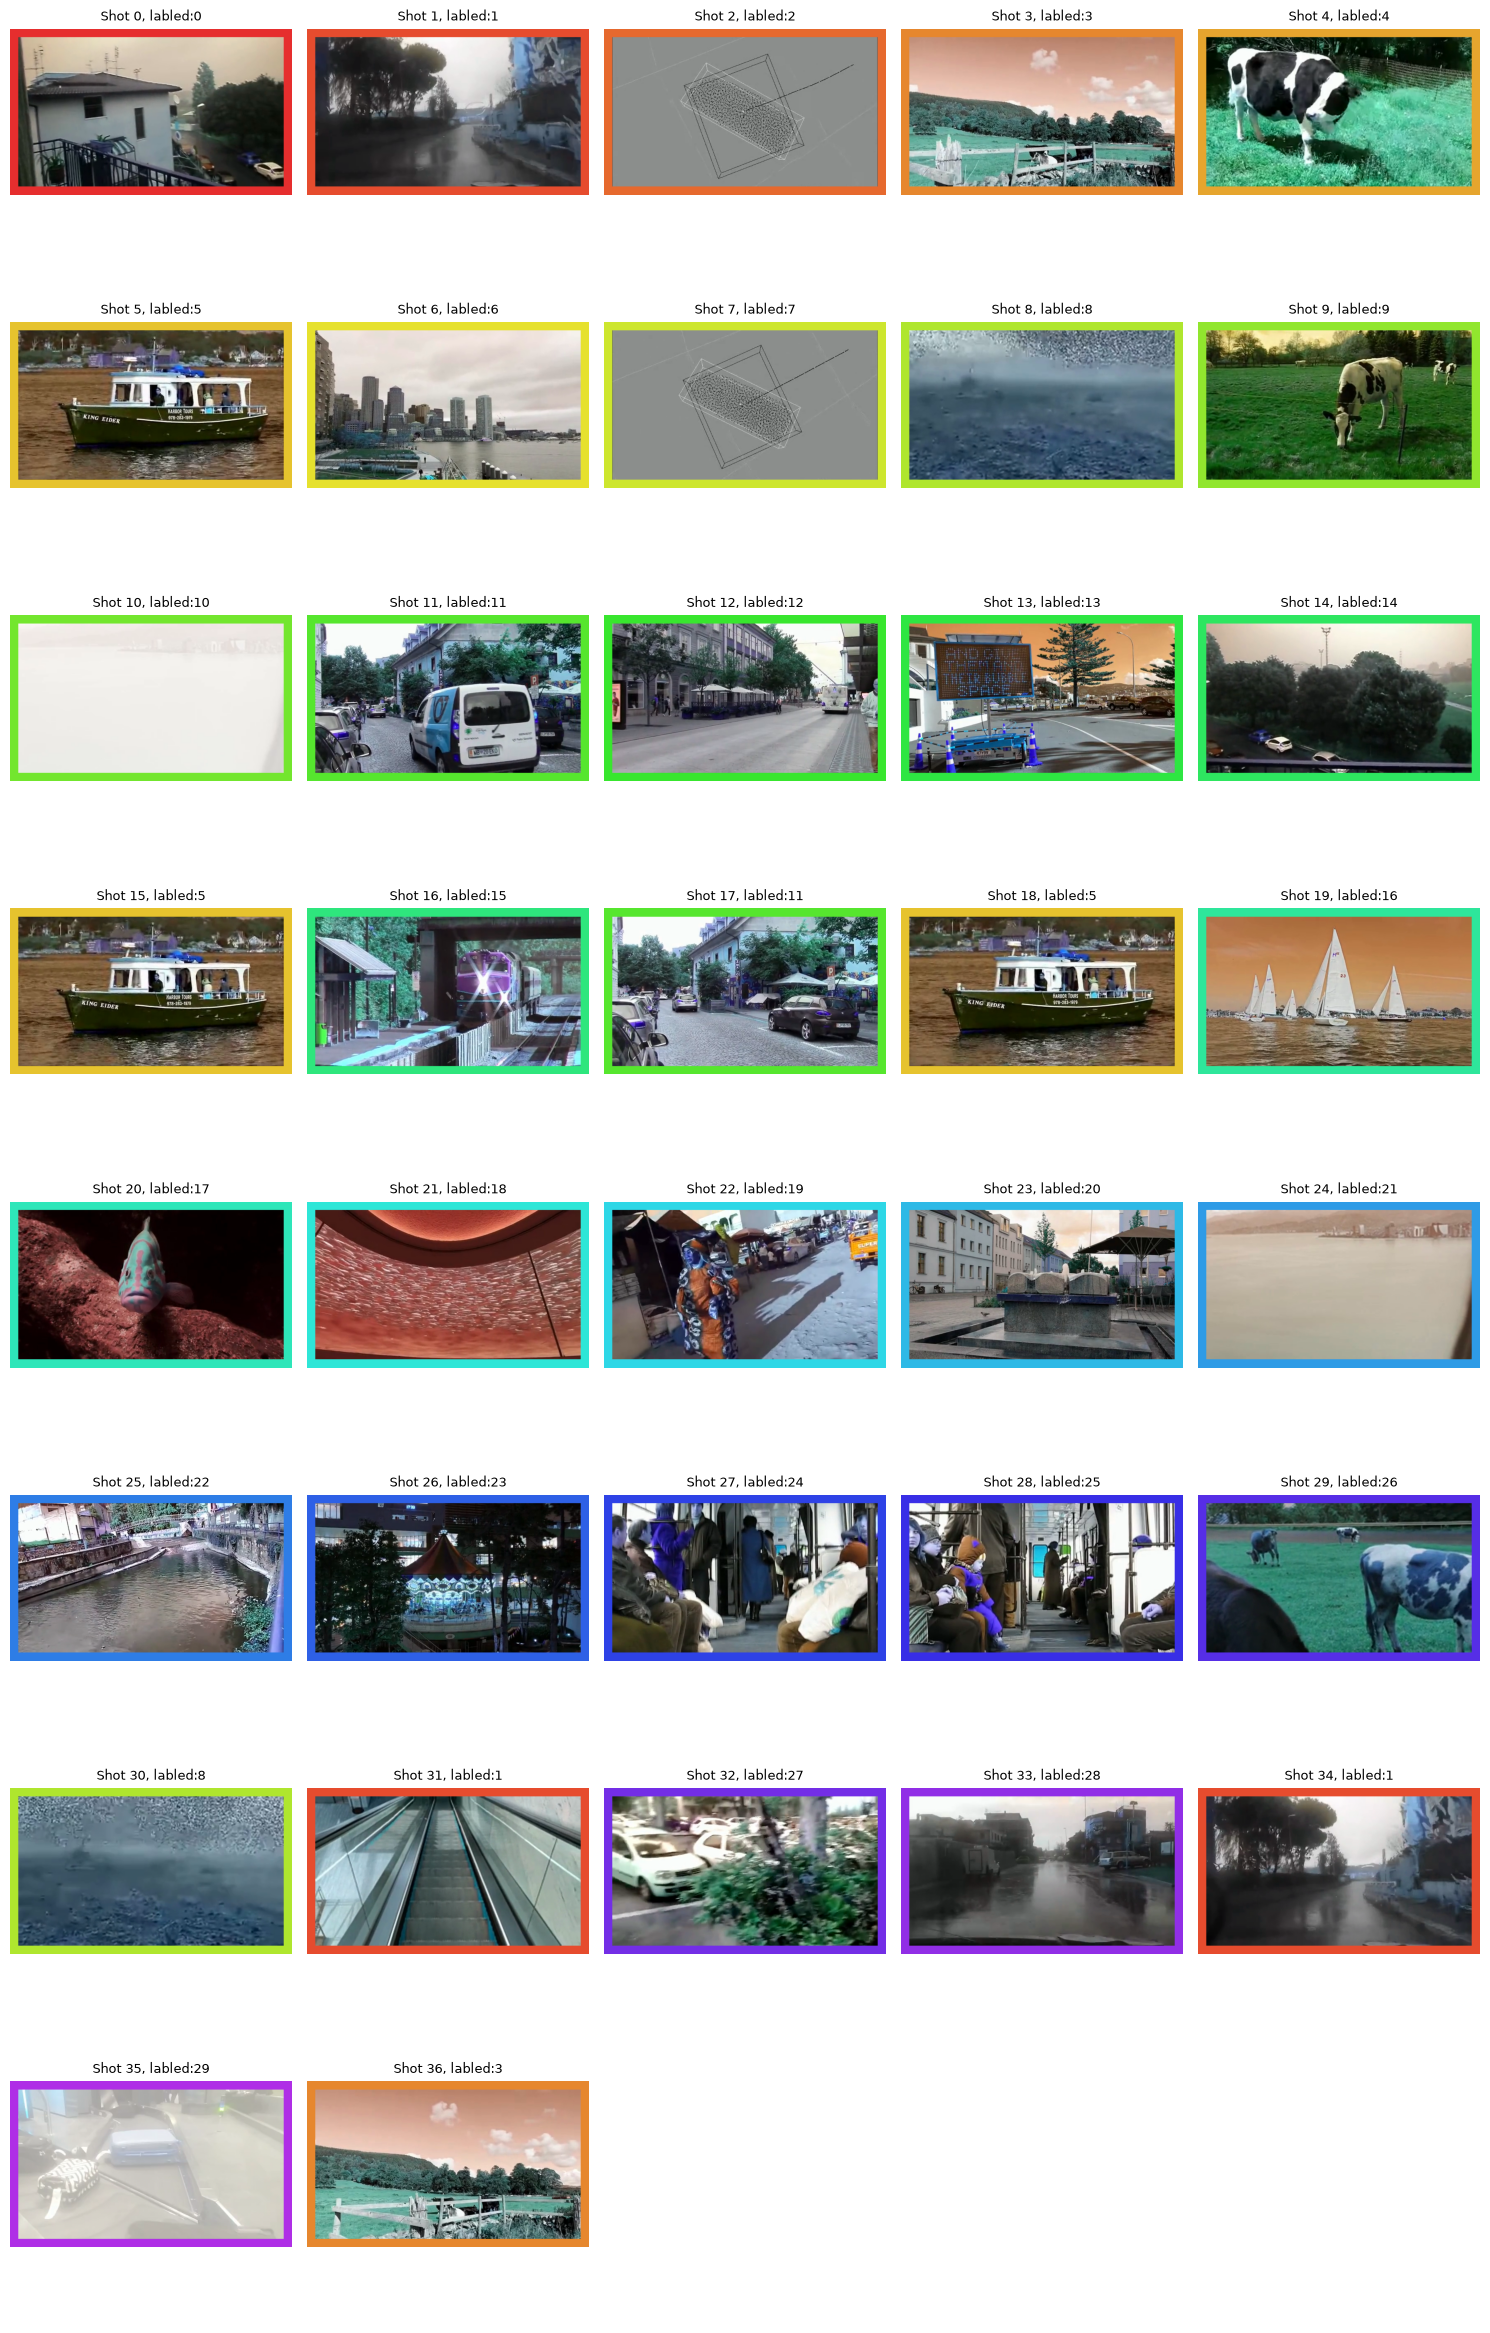

In [74]:
vc = cv.VideoCapture("../input/dev_01.mp4")
colors = generate_colors(37)
th = 0.8

labels = grouping.group_shots(shot_similarities, threshold=th)
scenes = {"scenes": {str(s["id"]): label for s, label in zip(shots, labels)}}

total_frames = []

for i in range(len(shots)):
  keyframe = tp1.extract_keyframes(shots[i], strategy="single_middle")
  vc.set(cv.CAP_PROP_POS_FRAMES, keyframe[0])

  ret, frame = vc.read()
  if ret:

    label = scenes["scenes"][str(i)]
    # create a border of a specfic color (here: black) and apply to image
    color = colors[label]
    img_with_border = cv.copyMakeBorder(frame, 20,20,20,20, cv.BORDER_CONSTANT, value=color)
    total_frames.append(img_with_border)

show_images(total_frames, 5, 3, scenes)

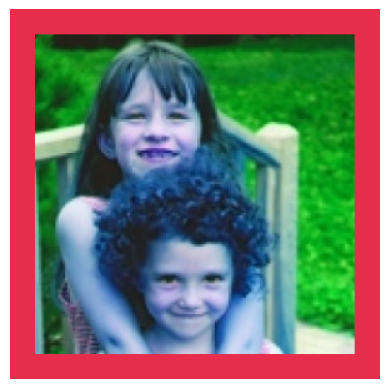

In [56]:
colors = generate_colors(37)
black_border_img = cv.copyMakeBorder(girls, 20,20,20,20, cv.BORDER_CONSTANT, value=colors[36])

plt.imshow(black_border_img)
plt.axis("off")
plt.show()

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools